# Downstream analysis on spatial multi-omics data of mouse brain with Parkinson's disease

In this tutorial, we will perform downstream analysis of spatial multi-omics data from the mouse brain with Parkinson’s disease, including identification of MCC flow, group-level MCC, MCC remodelling in receiver cells.

In [1]:
# Importing packages
import os
import metachat as mc
import scanpy as sc

import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# This notebook expects to run from the folder that contains the `datasets/`
# directory downloaded from Zenodo. If you started Jupyter somewhere else,
# point it here first, for example:
#     os.chdir("/path/to/the/folder/that/contains/datasets")


## Import MetaChat results 

We manually annotated the MetaChat result using Napari, dividing the left hemisphere as "Intact" and the right hemisphere as "Lesion". For convenience, we will directly import the annotated h5ad.

In [3]:
adata = sc.read('datasets/mouse_brain_parkinson/metachat_result_divided.h5ad')

The original output of MetaChat provides MCC signals for each individual metabolite–sensor pair.
Here, we use `mc.tl.summary_communication` to summarize the overall MCC activity associated with specific metabolites (e.g., dopamine and norepinephrine), aggregating their communication strengths across all corresponding sensors.

In [4]:
sum_metabolites = ['HMDB0000216', 'HMDB0000073']
mc.tl.summary_communication(adata = adata,
                            database_name = 'MetaChatDB',
                            sum_metabolites = sum_metabolites)

## MCC flow

Then, we can compute the vector field of MCC flow using `mc.tl.communication_flow`, which estimates the spatial directionality and magnitude of MCC based on the summarized metabolite signals.

In [5]:
mc.tl.communication_flow(adata = adata,
                         database_name = 'MetaChatDB',
                         sum_metabolites = sum_metabolites,
                         k = 5)

The output vector fields are saved in adata.obsm, e.g., `'MetaChat-vf-MetaChatDB-sender-HMDB0000216'` and `'MetaChat-vf-MetaChatDB-receiver-HMDB0000216'`, corresponding to the sender and receiver flows of each metabolite.

### HMDB0000073: Dopamine

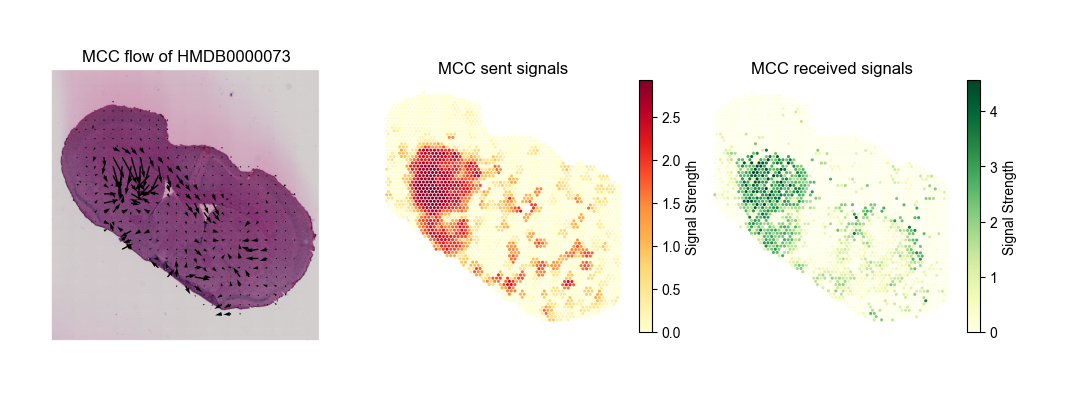

In [6]:
metabolite_name = "HMDB0000073"
fig, ax = plt.subplots(1, 3, figsize=(12,4))
pl1 = mc.pl.plot_communication_flow(adata = adata, 
                                    database_name = 'MetaChatDB',
                                    metabolite_name = metabolite_name,
                                    plot_method = 'grid',
                                    background = 'image',
                                    summary = 'sender',
                                    ndsize = 3,
                                    normalize_v_quantile = 0.995,
                                    grid_density = 0.5,
                                    title = f'MCC flow of {metabolite_name}',   
                                    ax = ax[0])
ax[0].set_box_aspect(1)

pl2 = mc.pl.plot_communication_flow(adata = adata, 
                                    database_name = 'MetaChatDB',
                                    metabolite_name = metabolite_name,
                                    plot_method = None,
                                    background = 'summary',
                                    summary = 'sender',
                                    cmap = 'YlOrRd',
                                    ndsize = 5,
                                    normalize_v_quantile = 0.995,
                                    title = 'MCC sent signals',   
                                    ax = ax[1])
ax[1].set_box_aspect(1)

pl3 = mc.pl.plot_communication_flow(adata = adata, 
                                    database_name = 'MetaChatDB',
                                    metabolite_name = metabolite_name,
                                    plot_method = None,
                                    background = 'summary',
                                    summary = 'receiver',
                                    cmap = 'YlGn',
                                    ndsize = 5,
                                    normalize_v_quantile = 0.995,
                                    title = 'MCC received signals',   
                                    ax = ax[2])
ax[2].set_box_aspect(1)

We can visualize which metabolite–sensor pairs contribute most to the overall MCC signals of a specific metabolite across tissue types using `mc.pl.plot_MSpair_contribute_group`.

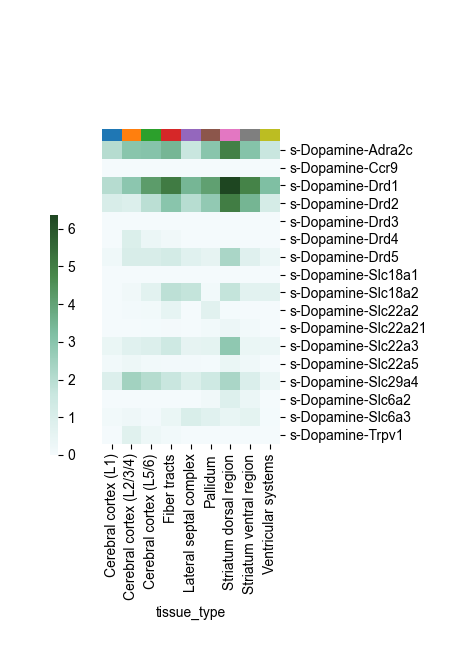

In [7]:
mc.pl.plot_MSpair_contribute_group(adata = adata, 
                                   database_name = 'MetaChatDB',
                                   group_name = 'tissue_type',
                                   metabolite_name = metabolite_name,
                                   summary = 'sender',
                                   cmap = 'green',
                                   figsize = (4,6))

### HMDB0000216: Norepinephrine

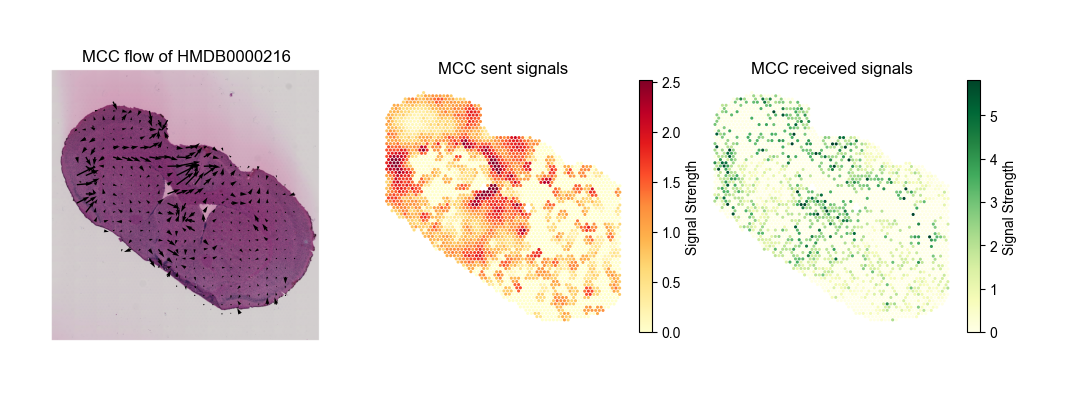

In [8]:
metabolite_name = "HMDB0000216"
fig, ax = plt.subplots(1, 3, figsize=(12,4))
pl1 = mc.pl.plot_communication_flow(adata = adata, 
                                    database_name = 'MetaChatDB',
                                    metabolite_name = metabolite_name,
                                    plot_method = 'grid',
                                    background = 'image',
                                    summary = 'sender',
                                    ndsize = 3,
                                    normalize_v_quantile = 0.995,
                                    grid_density = 0.5,
                                    title = f'MCC flow of {metabolite_name}',   
                                    ax = ax[0])
ax[0].set_box_aspect(1)

pl2 = mc.pl.plot_communication_flow(adata = adata, 
                                    database_name = 'MetaChatDB',
                                    metabolite_name = metabolite_name,
                                    plot_method = None,
                                    background = 'summary',
                                    summary = 'sender',
                                    cmap = 'YlOrRd',
                                    ndsize = 5,
                                    normalize_v_quantile = 0.995,
                                    title = 'MCC sent signals',   
                                    ax = ax[1])
ax[1].set_box_aspect(1)

pl3 = mc.pl.plot_communication_flow(adata = adata, 
                                    database_name = 'MetaChatDB',
                                    metabolite_name = metabolite_name,
                                    plot_method = None,
                                    background = 'summary',
                                    summary = 'receiver',
                                    cmap = 'YlGn',
                                    ndsize = 5,
                                    normalize_v_quantile = 0.995,
                                    title = 'MCC received signals',   
                                    ax = ax[2])
ax[2].set_box_aspect(1)

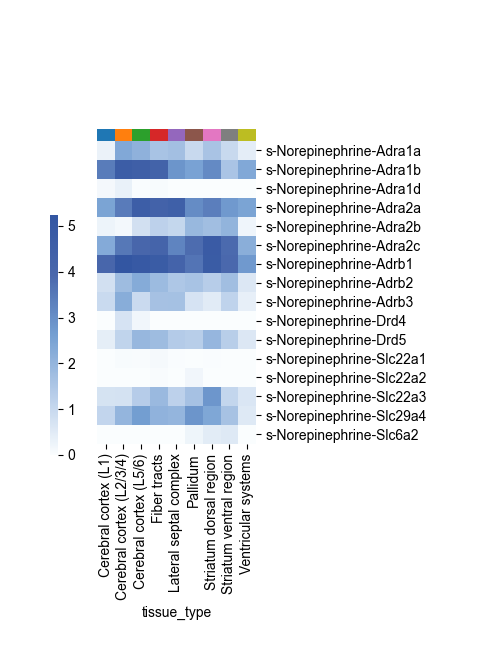

In [9]:
mc.pl.plot_MSpair_contribute_group(adata = adata, 
                                   database_name = 'MetaChatDB',
                                   group_name = 'tissue_type',
                                   metabolite_name = metabolite_name,
                                   summary = 'sender',
                                   cmap = 'blue',
                                   figsize = (4,6))

## MCC remodelling in receiver cells

In the next step, we aim to identify response genes in receiver cells. To do this, we provide the corresponding raw RNA data (`adata_raw`) as reference, which allows MetaChat to estimate transcriptional changes associated with signaling activity.

In [10]:
adata_raw = sc.read('datasets/mouse_brain_parkinson/adata_RNA_raw.h5ad')

### HMDB0000073: Dopamine

The function `mc.tl.communication_responseGenes` supports identifying response genes within a defined spatial subset of the tissue, allowing users to focus on specific regions or cell groups where the received signal is most relevant.

In [11]:
metabolite_name = 'HMDB0000073'
df_deg, df_yhat = mc.tl.communication_responseGenes(adata = adata,
                                                    adata_raw = adata_raw,
                                                    database_name = 'MetaChatDB',
                                                    metabolite_name = metabolite_name,
                                                    subgroup = ['Striatum dorsal region', 'Striatum ventral region'],
                                                    group_name = 'tissue_type',
                                                    summary = 'receiver')

/opt/conda/envs/metachat_04152026/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0/100 [00:00<?, ?/s]

  1%|          | 1/100 [00:00<00:19,  5.00/s]

  2%|▏         | 2/100 [00:00<00:15,  6.46/s]

  3%|▎         | 3/100 [00:00<00:13,  7.38/s]

...

use sequential method,

2

use subsampling method


Running Clustering on Parameter Combinations...


done.


Next, we clustered the response genes based on their expression trends along the received signaling strength. This allows us to identify distinct transcriptional programs that are activated or suppressed in response to MCC signal.

In [12]:
df_deg_clus, df_yhat_clus = mc.tl.communication_responseGenes_cluster(df_deg.iloc[:,:3], df_yhat, deg_clustering_res=0.3)

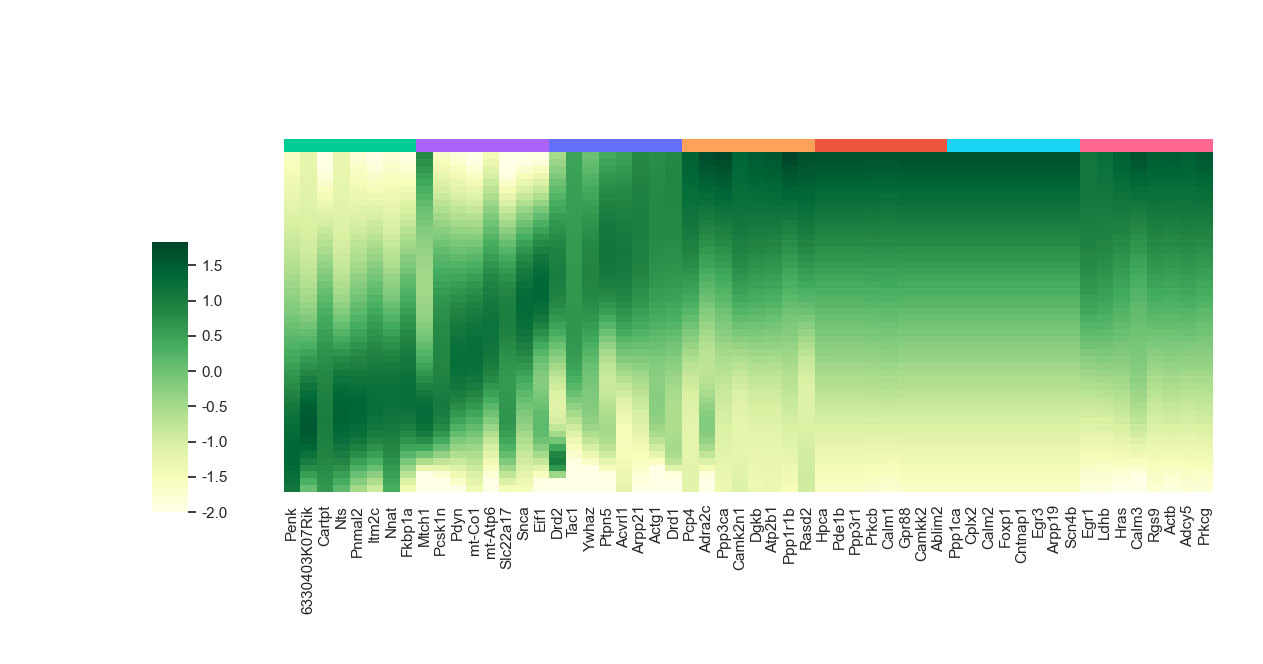

In [13]:
mc.pl.plot_communication_responseGenes(
    df_deg = df_deg_clus,
    df_yhat = df_yhat_clus,
    top_ngene_per_cluster = 8,
    colormap = 'YlGn',
    color_range = (-2,2),
    font_scale = 1,
    figsize = (12,6),
    return_genes = False
)

In [14]:
kegg_result = mc.tl.communication_responseGenes_keggEnrich(
    gene_list = df_deg[df_deg['pvalue'] < 0.05].index.tolist()[:1000],
    gene_sets = "KEGG_2019_Mouse",
    organism = "Mouse")

<Axes: xlabel='-log10(p-value)', ylabel='KEGG pathway'>

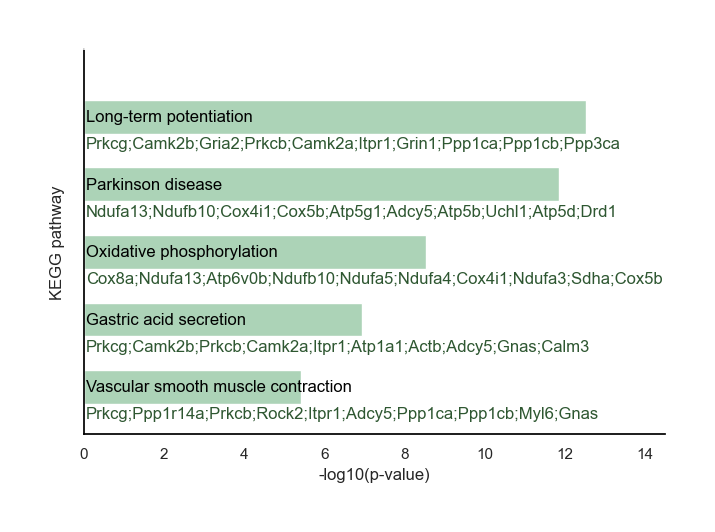

In [15]:
mc.pl.plot_communication_responseGenes_keggEnrich(
    df_result = kegg_result,
    show_term_order = [2,5,11,17,25],
    cmap = 'green',
    maxshow_gene = 10,
    organism = "Mouse",
    figsize = (7.5,5))

### HMDB0000216: Norepinephrine

In [16]:
adata_raw = sc.read('datasets/mouse_brain_parkinson/adata_RNA_raw.h5ad')

In [17]:
metabolite_name = 'HMDB0000216'
df_deg, df_yhat = mc.tl.communication_responseGenes(
    adata = adata,
    adata_raw = adata_raw,
    database_name = 'MetaChatDB',
    metabolite_name = metabolite_name,
    subgroup = ['Cerebral cortex (L1)', 'Cerebral cortex (L2/3/4)', 'Cerebral cortex (L5/6)'],
    group_name = 'tissue_type',
    summary = 'receiver'
)

  0%|          | 0/100 [00:00<?, ?/s]

  1%|          | 1/100 [00:00<00:24,  4.07/s]

  2%|▏         | 2/100 [00:00<00:16,  5.82/s]

  3%|▎         | 3/100 [00:00<00:14,  6.70/s]

  4%|▍         | 4/100 [00:00<00:13,  6.97/s]

...

use sequential method,

2

use subsampling method


Running Clustering on Parameter Combinations...


done.


In [18]:
df_deg_clus, df_yhat_clus = mc.tl.communication_responseGenes_cluster(df_deg.iloc[:,:3], df_yhat, deg_clustering_res=0.3)

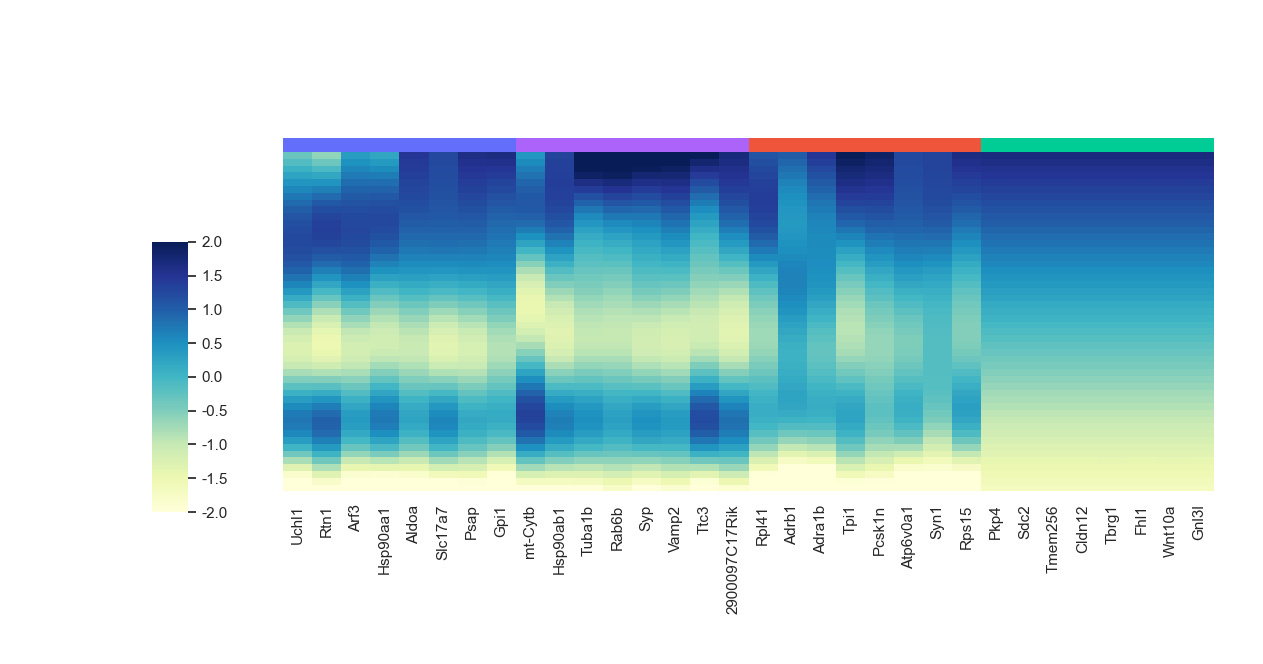

In [19]:
mc.pl.plot_communication_responseGenes(
    df_deg = df_deg_clus,
    df_yhat = df_yhat_clus,
    top_ngene_per_cluster = 8,
    colormap = 'YlGnBu',
    color_range = (-2,2),
    font_scale = 1,
    figsize = (12,6),
    return_genes = False
)

In [20]:
kegg_result_subgroup = mc.tl.communication_responseGenes_keggEnrich(
    gene_list = df_deg[df_deg['pvalue'] < 0.05].index.tolist()[:1000],
    gene_sets = "KEGG_2019_Mouse",
    organism = "Mouse"
)

<Axes: xlabel='-log10(p-value)', ylabel='KEGG pathway'>

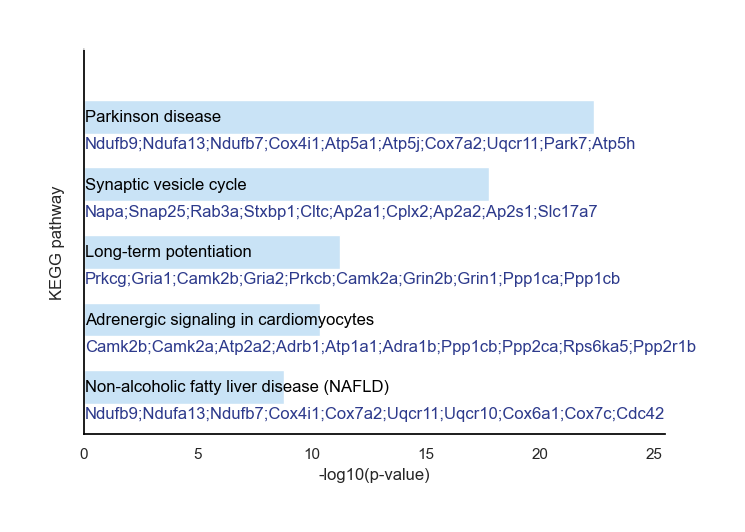

In [21]:
mc.pl.plot_communication_responseGenes_keggEnrich(
    df_result = kegg_result_subgroup,
    show_term_order = [3,5,7,10,14],
    cmap = 'blue',
    maxshow_gene = 10,
    organism = "Mouse",
    figsize = (7.5,5)
)